## Setup and download


In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = yf.download("AAPL", start="2025-01-01", end="2026-01-01")
df.head()

/tmp/ipykernel_872/2591390852.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("AAPL", start="2025-01-01", end="2026-01-01")
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2025-01-02,242.093140,247.305315,240.077766,247.136526,55740700
2025-01-03,241.606644,242.420728,240.147234,241.606644,40244100
2025-01-06,243.234848,245.548063,241.447813,242.549817,45045600
2025-01-07,240.464951,243.780883,239.611146,241.229392,40856000
2025-01-08,240.951416,241.954149,238.320515,240.177037,37628900


In [3]:
# If the index is MultiIndex, flatten it
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)
df.head()

Price,Close,High,Low,Open,Volume
Date,,,,,
2025-01-02,242.093140,247.305315,240.077766,247.136526,55740700
2025-01-03,241.606644,242.420728,240.147234,241.606644,40244100
2025-01-06,243.234848,245.548063,241.447813,242.549817,45045600
2025-01-07,240.464951,243.780883,239.611146,241.229392,40856000
2025-01-08,240.951416,241.954149,238.320515,240.177037,37628900


## Simple Moving Average (SMA)

In [4]:
df['SMA_20'] = df['Close'].rolling(window=20).mean()

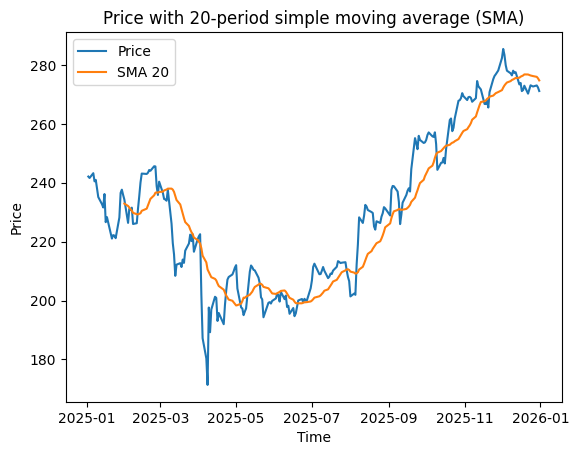

In [5]:
plt.plot(df['Close'], label='Price')
plt.plot(df['SMA_20'], label='SMA 20')
plt.title("Price with 20-period simple moving average (SMA)")
plt.xlabel("Time")
plt.ylabel("Price")
plt.legend()
plt.show()

## Exponential Moving Average (EMA)

In [6]:
df['EMA_20'] = df['Close'].ewm(span=20, adjust=False).mean()

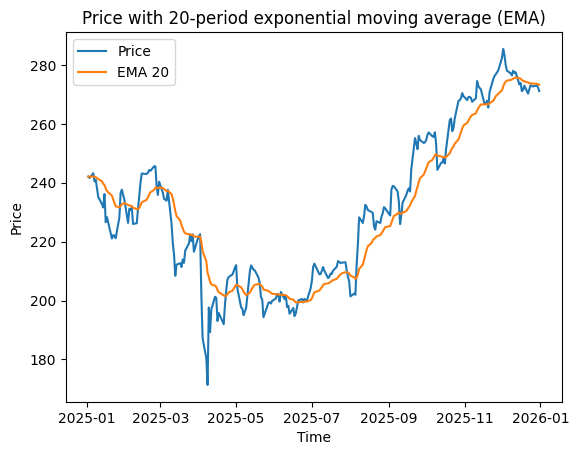

In [7]:
plt.plot(df['Close'], label='Price')
plt.plot(df['EMA_20'], label='EMA 20')
plt.title("Price with 20-period exponential moving average (EMA)")
plt.xlabel("Time")
plt.ylabel("Price")
plt.legend()
plt.show()

## Comparing SMA and EMA

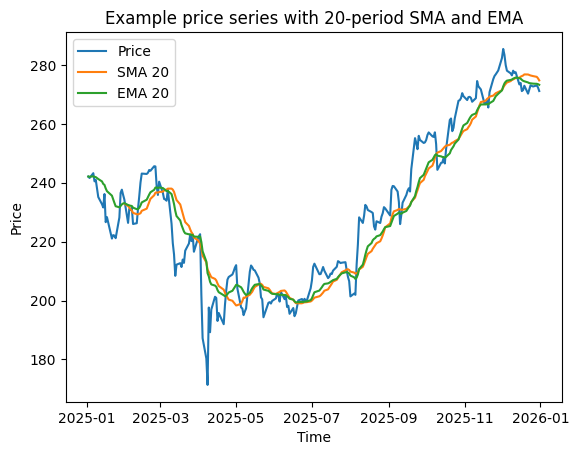

In [8]:
plt.plot(df['Close'], label='Price')
plt.plot(df['SMA_20'], label='SMA 20')
plt.plot(df['EMA_20'], label='EMA 20')
plt.title("Example price series with 20-period SMA and EMA")
plt.xlabel("Time")
plt.ylabel("Price")
plt.legend()
plt.show()

## Relative Strength Index (RSI)

In [9]:
delta = df['Close'].diff()

In [10]:
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

In [11]:
window = 14
avg_gain = gain.rolling(window).mean()
avg_loss = loss.rolling(window).mean()

In [12]:
for i in range(window + 1, len(df)):
  avg_gain.iloc[i] = (
    avg_gain.iloc[i - 1] * (window - 1) + gain.iloc[i]
  ) / window

  avg_loss.iloc[i] = (
    avg_loss.iloc[i - 1] * (window - 1) + loss.iloc[i]
  ) / window

In [13]:
rs = avg_gain / avg_loss

In [14]:
df['RSI'] = 100 - (100 / (1 + rs))

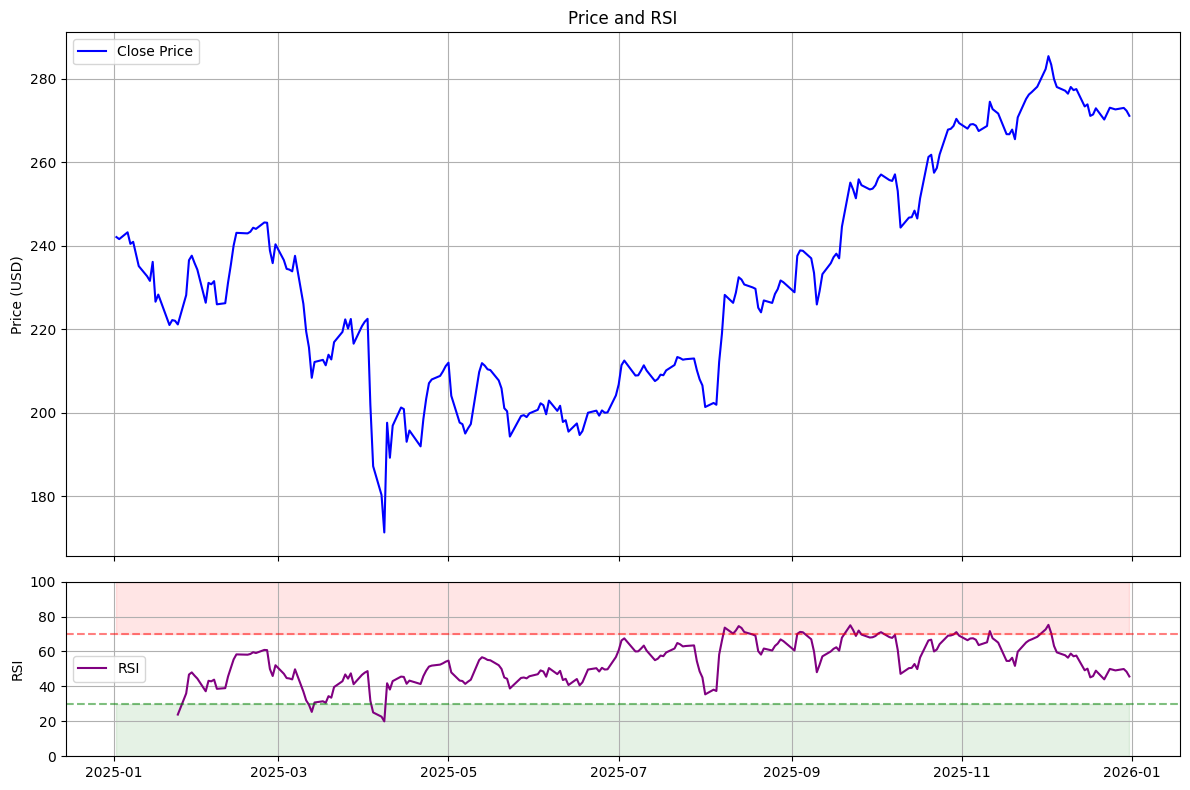

In [15]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(12, 8), gridspec_kw={'height_ratios': [3, 1]})

# Plot Price
ax1.plot(df.index, df['Close'], label='Close Price', color='blue')
ax1.set_title(f"Price and RSI")
ax1.set_ylabel("Price (USD)")
ax1.legend()
ax1.grid(True)

# Plot RSI
ax2.plot(df.index, df['RSI'], label='RSI', color='purple')
ax2.axhline(70, color='red', linestyle='--', alpha=0.5)
ax2.axhline(30, color='green', linestyle='--', alpha=0.5)
ax2.fill_between(df.index, 70, 100, color='red', alpha=0.1)
ax2.fill_between(df.index, 0, 30, color='green', alpha=0.1)
ax2.set_ylabel("RSI")
ax2.set_ylim(0, 100)
ax2.legend()
ax2.grid(True)

plt.tight_layout()

## Moving Average Convergence Divergence (MACD)

In [16]:
fast_ema = df['Close'].ewm(span=12, adjust=False).mean()
slow_ema = df['Close'].ewm(span=26, adjust=False).mean()

In [17]:
df['MACD'] = fast_ema - slow_ema
df['Signal'] = df['MACD'].ewm(span=9, adjust=False).mean()
df['Histogram'] = df['MACD'] - df['Signal']

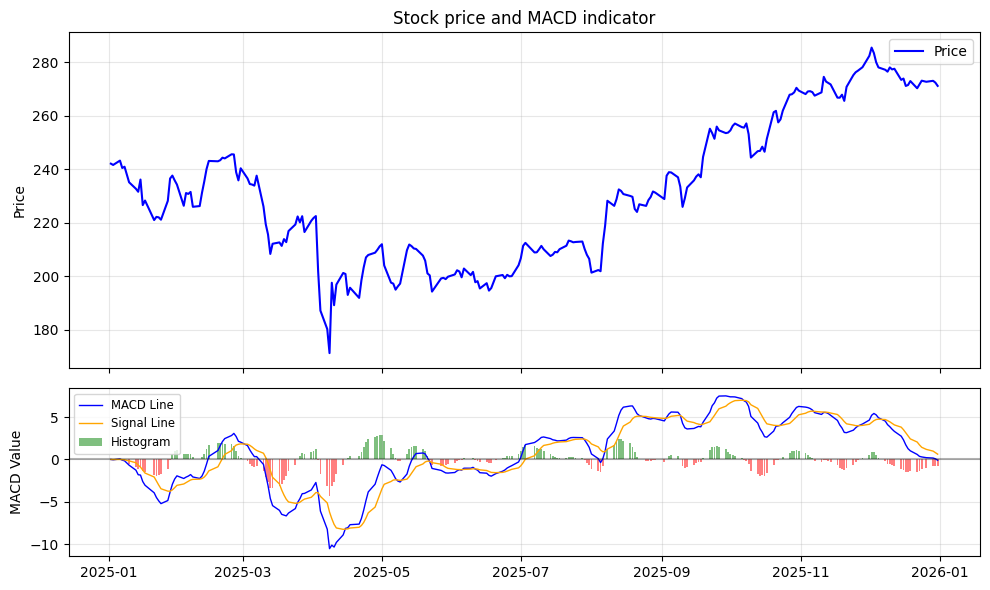

In [18]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 6), gridspec_kw={'height_ratios': [3, 1.5]})

# Price plot
ax1.plot(df.index, df['Close'], color='blue', label='Price')
ax1.set_title("Stock price and MACD indicator")
ax1.set_ylabel("Price")
ax1.grid(True, alpha=0.3)
ax1.legend()

# MACD plot
ax2.plot(df.index, df['MACD'], color='blue', label='MACD Line', linewidth=1)
ax2.plot(df.index, df['Signal'], color='orange', label='Signal Line', linewidth=1)

# Histogram
colors = ['green' if x >= 0 else 'red' for x in df['Histogram']]
ax2.bar(df.index, df['Histogram'], color=colors, alpha=0.5, label='Histogram')

ax2.axhline(0, color='black', linestyle='-', alpha=0.3)
ax2.set_ylabel("MACD Value")
ax2.grid(True, alpha=0.3)
ax2.legend(loc='upper left', fontsize='small')

plt.tight_layout()

In [19]:
returns = df['Close'].pct_change()
df['Volatility'] = returns.rolling(window=20).std()
df['Volatility'] = df['Volatility'] * np.sqrt(252) * 100 # Annualized % - optional

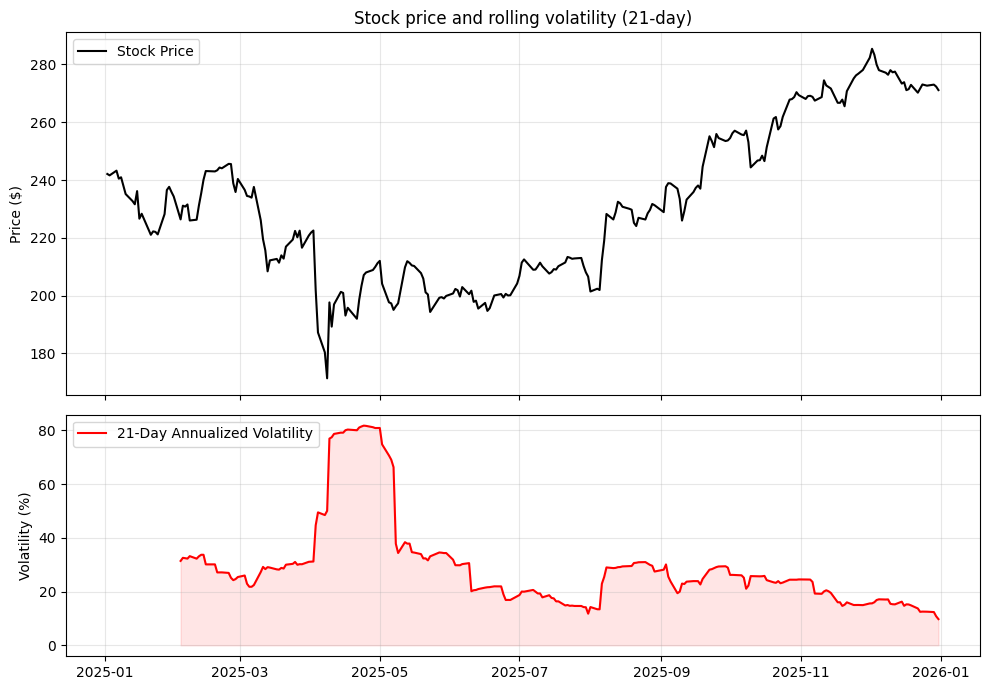

In [20]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 7),
                               gridspec_kw={'height_ratios': [3, 2]})

# Top Plot: Price
ax1.plot(df.index, df['Close'], color='black', label='Stock Price')
ax1.set_title("Stock price and rolling volatility (21-day)")
ax1.set_ylabel("Price ($)")
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.3)

# Bottom Plot: Rolling Volatility
ax2.plot(df.index, df['Volatility'], color='red', label='21-Day Annualized Volatility')
ax2.set_ylabel("Volatility (%)")
ax2.legend(loc='upper left')
ax2.grid(True, alpha=0.3)
ax2.fill_between(df.index, df['Volatility'], color='red', alpha=0.1)

plt.tight_layout()

## Bollinger Bands

In [21]:
window = 20
k = 2

In [22]:
sma = df['Close'].rolling(window).mean()
std = df['Close'].rolling(window).std(ddof=0)

In [23]:
df['Upper'] = sma + k * std
df['Lower'] = sma - k * std

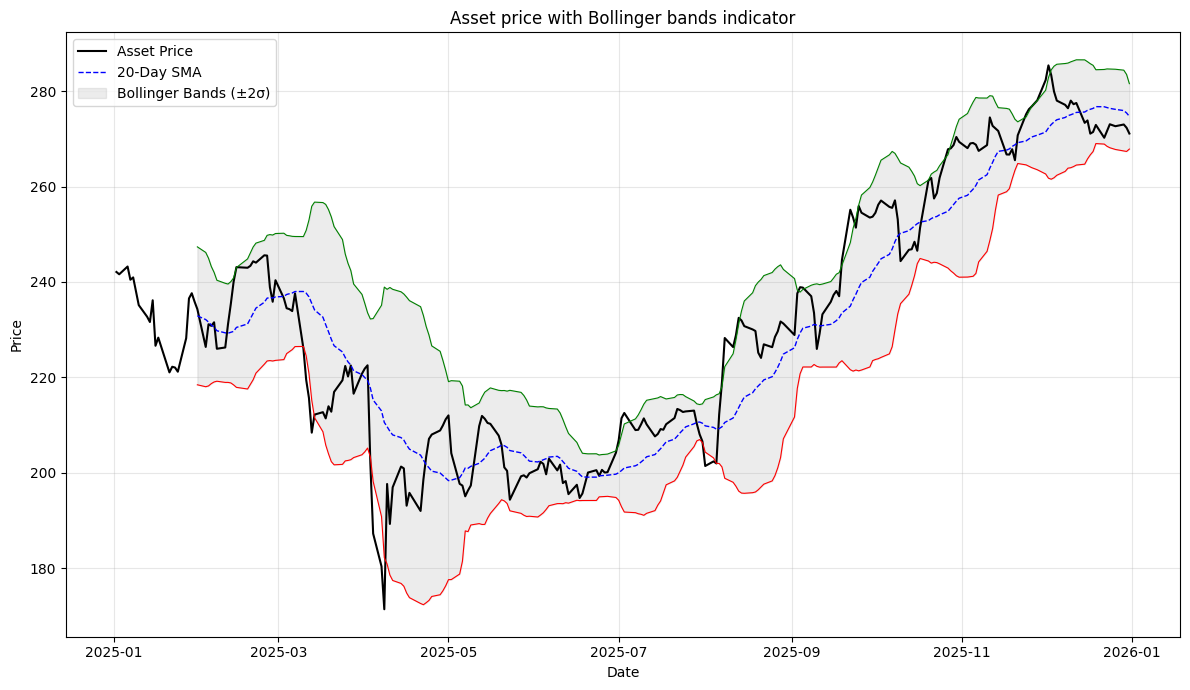

In [24]:
plt.figure(figsize=(12, 7))

# Plot Price, SMA, and Bands
plt.plot(df.index, df['Close'], color='black', linewidth=1.5, label='Asset Price')
plt.plot(df.index, sma, color='blue', linestyle='--', linewidth=1, label='20-Day SMA')
plt.plot(df.index, df['Upper'], color='green', linewidth=0.8)
plt.plot(df.index, df['Lower'], color='red', linewidth=0.8)

# Shaded Area Between Bands
plt.fill_between(df.index, df['Lower'], df['Upper'], color='gray', alpha=0.15, label='Bollinger Bands (±2σ)')

# Formatting
plt.title("Asset price with Bollinger bands indicator")
plt.ylabel("Price")
plt.xlabel("Date")
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left')

plt.tight_layout()

## Average True Range (ATR)

In [25]:
high = df['High']
low = df['Low']
close = df['Close']

In [26]:
tr = pd.concat([
   high - low,
   (high - close.shift()).abs(),
   (low - close.shift()).abs()
], axis=1).max(axis=1)

In [27]:
df['ATR'] = tr.rolling(14).mean()

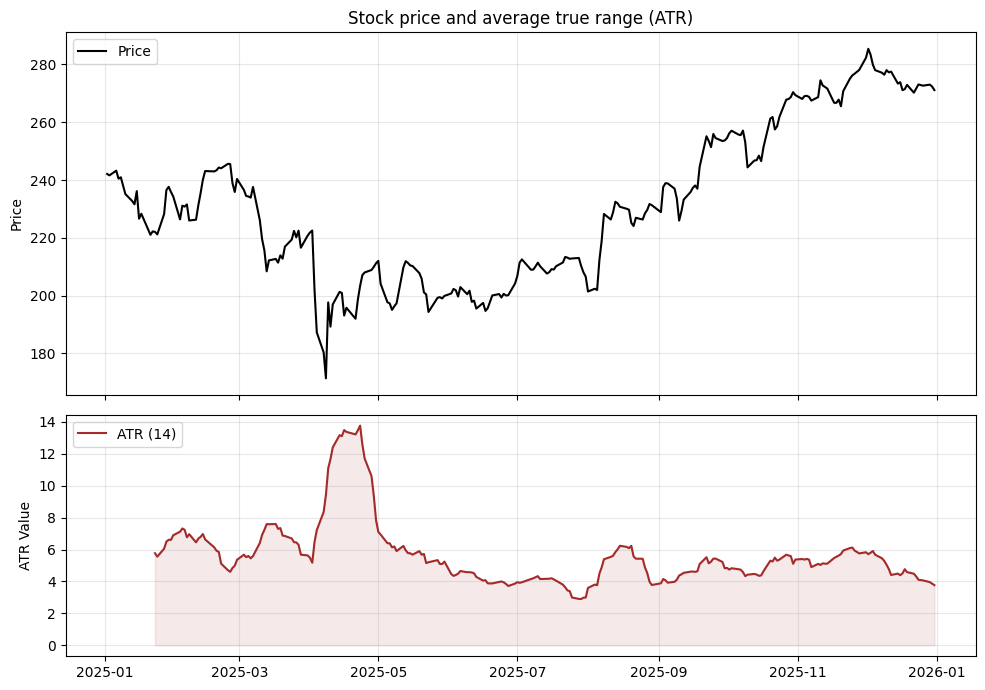

In [28]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 7),
                               gridspec_kw={'height_ratios': [3, 2]})

# Top Plot: Price
ax1.plot(df.index, df['Close'], color='black', linewidth=1.5, label='Price')
ax1.set_title("Stock price and average true range (ATR)")
ax1.set_ylabel("Price")
ax1.grid(True, alpha=0.3)
ax1.legend(loc='upper left')

# Bottom Plot: ATR
ax2.plot(df.index, df['ATR'], color='brown', label='ATR (14)')
ax2.fill_between(df.index, df['ATR'], color='brown', alpha=0.1)
ax2.set_ylabel("ATR Value")
ax2.grid(True, alpha=0.3)
ax2.legend(loc='upper left')

plt.tight_layout()